<a href="https://colab.research.google.com/github/gttfg/Algorithm-Practice/blob/main/TIE_Fighter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
%%writefile my_utils.py

import numpy as np
from matplotlib.patches import Polygon

MAIN_COLOR = '#287FB5'

# 2차원 변환 함수

def translate(p, dx, dy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, dx],
        [0.0, 1.0, dy],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [np.cos(theta), -np.sin(theta), 0.0],
        [np.sin(theta),  np.cos(theta), 0.0],
        [0.0,            0.0,           1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [sx,  0.0, 0.0],
        [0.0, sy,  0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, sx,  0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, 0.0],
        [sy,  1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0,  0.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0,  0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [-1.0, 0.0, 0.0],
        [0.0,  1.0, 0.0],
        [0.0,  0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [-1.0,  0.0, 0.0],
        [0.0,  -1.0, 0.0],
        [0.0,   0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def reflect_y_equal_x(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [0.0, 1.0, 0.0],
        [1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 기본 그리기 함수

def draw_rectangle(ax, points, facecolor=MAIN_COLOR, edgecolor=MAIN_COLOR):
    polygon = Polygon(
        points,
        closed=True,
        facecolor=facecolor,
        edgecolor=edgecolor
    )
    ax.add_patch(polygon)


def center_rectangle(points, LEN):
    result = []
    for p in points:
        q = translate(p, -LEN / 2, -LEN / 2)
        result.append(q)
    return result


def make_base_rectangle(LEN):
    p1 = np.array([0.0, 0.0])
    p2 = np.array([LEN, 0.0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0.0, LEN])
    return [p1, p2, p3, p4]

# TIE Fighter 구성 요소

def get_cockpit(points, LEN):
    q = center_rectangle(points, LEN)
    q = [scale(p, 5.0, 5.0) for p in q]
    q = [rotate(p, np.pi / 4) for p in q]
    return q


def draw_cockpit(ax, points, LEN):
    q = get_cockpit(points, LEN)
    draw_rectangle(ax, q)


def get_left_upper_arm(points, LEN):
    q = center_rectangle(points, LEN)

    q = [scale(p, 5.3, 0.79) for p in q]

    q = [shear_y(p, 0.127) for p in q]

    q = [translate(p, -495, 38) for p in q]

    return q


def draw_left_arm(ax, points, LEN):

    upper = get_left_upper_arm(points, LEN)
    draw_rectangle(ax, upper)

    lower = [reflect_x(p) for p in upper]
    draw_rectangle(ax, lower)


def draw_right_arm(ax, points, LEN):

    left_upper = get_left_upper_arm(points, LEN)

    upper = [reflect_y(p) for p in left_upper]
    draw_rectangle(ax, upper)

    lower = [reflect_origin(p) for p in left_upper]
    draw_rectangle(ax, lower)


def get_left_upper_wing(points, LEN):

    q = center_rectangle(points, LEN)

    q = [scale(p, 1.1, 6.0) for p in q]

    q = [shear_y(p, -200 / 110) for p in q]

    q = [translate(p, -805, 200) for p in q]

    return q


def draw_left_wing(ax, points, LEN):

    upper = get_left_upper_wing(points, LEN)
    draw_rectangle(ax, upper)

    lower = [reflect_x(p) for p in upper]
    draw_rectangle(ax, lower)


def draw_right_wing(ax, points, LEN):

    left_upper = get_left_upper_wing(points, LEN)

    upper = [reflect_y(p) for p in left_upper]
    draw_rectangle(ax, upper)

    lower = [reflect_origin(p) for p in left_upper]
    draw_rectangle(ax, lower)


# 전체 물체

def draw_object(ax, LEN):

    points = make_base_rectangle(LEN)

    # 1. 중앙 조종석
    draw_cockpit(ax, points, LEN)

    # 2. 왼쪽 날개축
    draw_left_arm(ax, points, LEN)

    # 3. 왼쪽 날개
    draw_left_wing(ax, points, LEN)

    # 4. 오른쪽 날개축
    draw_right_arm(ax, points, LEN)

    # 5. 오른쪽 날개
    draw_right_wing(ax, points, LEN)

Overwriting my_utils.py


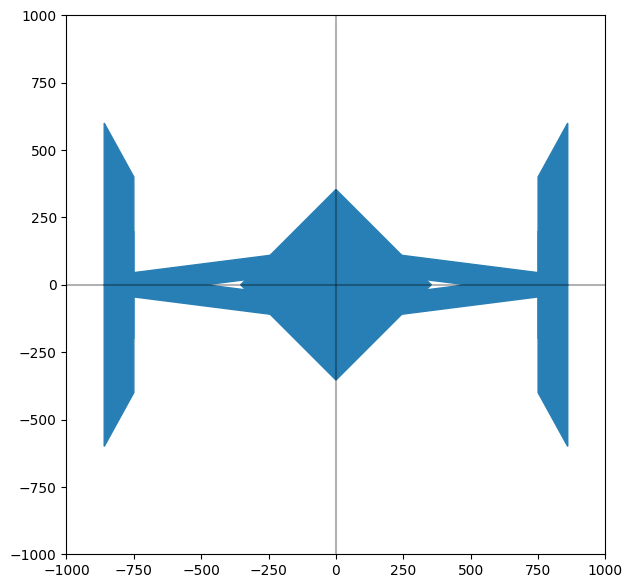

In [22]:
import matplotlib.pyplot as plt
import importlib
import my_utils

importlib.reload(my_utils)

INF = 1000
LEN = 100

def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)

    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

    ax.set_xticks(range(-1000, 1001, 250))
    ax.set_yticks(range(-1000, 1001, 250))

    ax.grid(False)

fig, ax = plt.subplots(figsize=(7, 7))

draw_axis(ax)

my_utils.draw_object(ax, LEN)

plt.show()